In [1]:
# Uncomment this to install
# %pip install tiktoken==0.8.0 -q
# %pip install seaborn


[notice] A new release of pip is available: 24.2 -> 24.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.2 -> 24.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from utils.utils import load_from_pickle, save_to_pickle


all_documents = load_from_pickle('all_documents')
# all_documents
# all_documents_batches = split_into_batches(all_documents, len(all_documents))

In [3]:
len(all_documents)

46409

In [4]:
test_doc = ""
for doc in all_documents:
    test_doc = doc.page_content # mungkin first line bisa dihapus, desc stat, make plot
    break
    
test_doc

'DOC NAME: Undang-undang Nomor 2 Tahun 1988 Tentang Prajurit Angkatan Bersenjata Ri | UNDANG-UNDANG\n\n \n \n \nUNDANG-UNDANG REPUBLIK INDONESIA \nNOMOR 2 TAHUN 1988 \nTENTANG \n \nPRAJURIT ANGKATAN BERSENJATA REPUBLIK INDONESIA \n \n \nDENGAN RAHMAT TUHAN YANG MAHA ESA \n \nPRESIDEN REPUBLIK INDONESIA, \n \nMenimbang : a. \nbahwa usaha pembelaan negara diselenggarakan dengan Sistem \nPertahanan Keamanan Rakyat Semesta, yang merupakan perjuangan \nsegenap rakyat Indonesia dalam bentuk perlawanan tidak bersenjata \ndan perlawanan bersenjata.   Perlawanan bersenjata rakyat Indonesia \ninilah melahirkan tentara rakyat yang teratur, yang kemudian \nmelembaga ke dalam wadah tunggal, yakni tentara kebangsaan \ndengan sebutan Tentara Nasional Indonesia berintikan Angkatan \nBersenjata Republik Indonesia;  \n \n \nb. \nbahwa anggota Angkatan Bersenjata Republik Indonesia Sukarela, \nanggota Angkatan Bersenjata Republik Indonesia Wajib, dan anggota \nCadangan Tentara Nasional Indonesia sebagaim

In [5]:
first_nl = test_doc.find("\n")
test_doc = test_doc[first_nl:]

In [6]:
test_doc

'\n\n \n \n \nUNDANG-UNDANG REPUBLIK INDONESIA \nNOMOR 2 TAHUN 1988 \nTENTANG \n \nPRAJURIT ANGKATAN BERSENJATA REPUBLIK INDONESIA \n \n \nDENGAN RAHMAT TUHAN YANG MAHA ESA \n \nPRESIDEN REPUBLIK INDONESIA, \n \nMenimbang : a. \nbahwa usaha pembelaan negara diselenggarakan dengan Sistem \nPertahanan Keamanan Rakyat Semesta, yang merupakan perjuangan \nsegenap rakyat Indonesia dalam bentuk perlawanan tidak bersenjata \ndan perlawanan bersenjata.   Perlawanan bersenjata rakyat Indonesia \ninilah melahirkan tentara rakyat yang teratur, yang kemudian \nmelembaga ke dalam wadah tunggal, yakni tentara kebangsaan \ndengan sebutan Tentara Nasional Indonesia berintikan Angkatan \nBersenjata Republik Indonesia;  \n \n \nb. \nbahwa anggota Angkatan Bersenjata Republik Indonesia Sukarela, \nanggota Angkatan Bersenjata Republik Indonesia Wajib, dan anggota \nCadangan Tentara Nasional Indonesia sebagaimana dimaksud dalam \nUndang-undang Nomor 20 Tahun 1982 yang telah diubah dengan \nUndang-undang No

In [7]:
import tiktoken

encoding = tiktoken.get_encoding("o200k_base")

In [8]:
%pip show tiktoken

Name: tiktoken
Version: 0.8.0
Summary: tiktoken is a fast BPE tokeniser for use with OpenAI's models
Home-page: https://github.com/openai/tiktoken
Author: Shantanu Jain
Author-email: shantanu@openai.com
License: MIT License
        
        Copyright (c) 2022 OpenAI, Shantanu Jain
        
        Permission is hereby granted, free of charge, to any person obtaining a copy
        of this software and associated documentation files (the "Software"), to deal
        in the Software without restriction, including without limitation the rights
        to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
        copies of the Software, and to permit persons to whom the Software is
        furnished to do so, subject to the following conditions:
        
        The above copyright notice and this permission notice shall be included in all
        copies or substantial portions of the Software.
        
        THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY K

In [9]:
from collections import defaultdict

doc_token = defaultdict(int)
for i, doc in enumerate(all_documents):
    token = encoding.encode(doc.page_content)
    # print(token)
    doc_token[i+1] = len(token) # desc stat, make plot

In [10]:
list(doc_token.items())[:10]

[(1, 569),
 (2, 741),
 (3, 607),
 (4, 608),
 (5, 494),
 (6, 588),
 (7, 556),
 (8, 482),
 (9, 585),
 (10, 581)]

In [11]:
# Extract keys and values for x and y plot
docs = list(doc_token.keys())
token_len = list(doc_token.values())

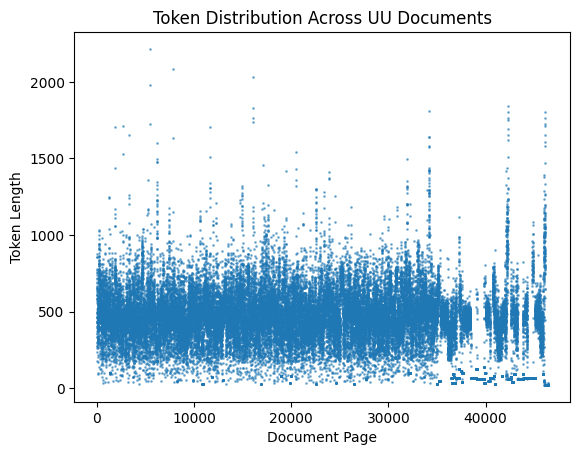

In [12]:
import matplotlib.pyplot as plt

# Create scatter plot
plt.scatter(docs, token_len, alpha=0.5, s=1)
plt.xlabel("Document Page")
plt.ylabel("Token Length")
plt.title("Token Distribution Across UU Documents")
plt.show()

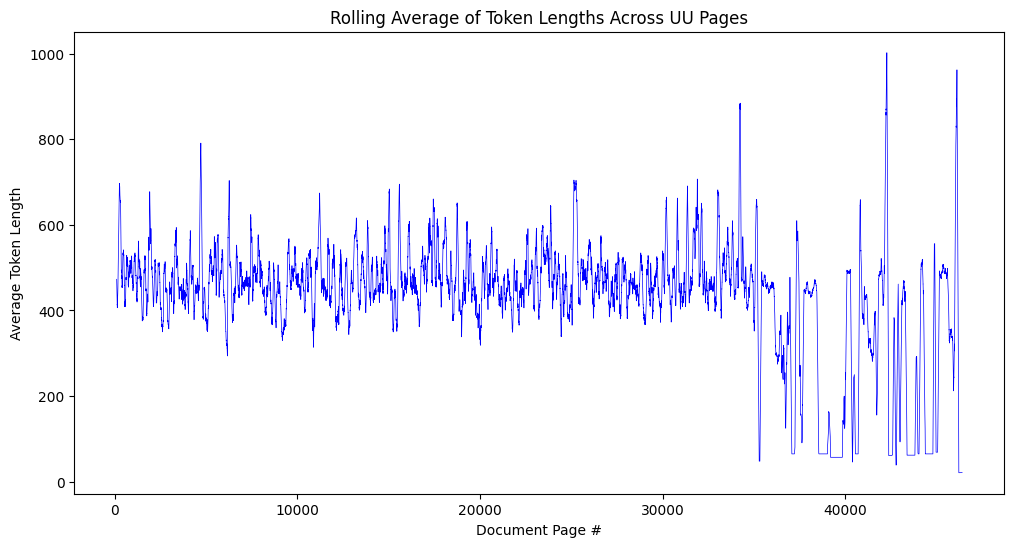

In [13]:
import pandas as pd

# Convert data to a DataFrame for easier manipulation
df = pd.DataFrame({"Page": docs, "Tokens": token_len})

# Calculate rolling mean (e.g., with a window of 100 pages)
df["Rolling_Tokens"] = df["Tokens"].rolling(window=100).mean()

plt.figure(figsize=(12, 6))
plt.plot(df["Page"], df["Rolling_Tokens"], color="blue", linewidth=0.5)
plt.xlabel("Document Page #")
plt.ylabel("Average Token Length")
plt.title("Rolling Average of Token Lengths Across UU Pages")
plt.show()

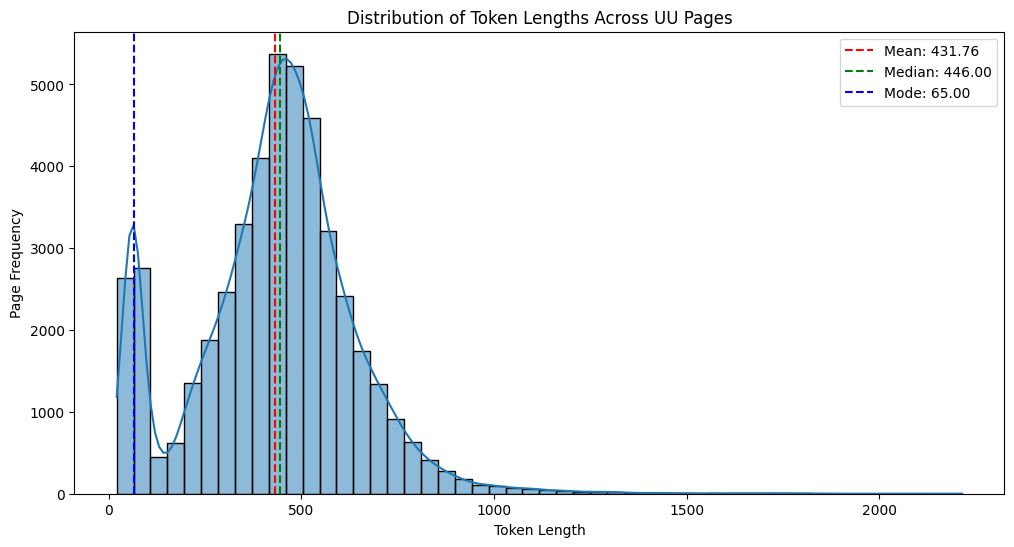

In [14]:
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.histplot(token_len, bins=50, kde=True)
plt.xlabel("Token Length")
plt.ylabel("Page Frequency")

token_series = pd.Series(token_len)

# Calculate descriptive statistics
mean = token_series.mean()
median = token_series.median()
mode = token_series.mode()[0]  # mode() returns a series; [0] gets the first mode

# Add lines for mean, median, and mode
plt.axvline(mean, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean:.2f}')
plt.axvline(median, color='green', linestyle='--', linewidth=1.5, label=f'Median: {median:.2f}')
plt.axvline(mode, color='blue', linestyle='--', linewidth=1.5, label=f'Mode: {mode:.2f}')

plt.title("Distribution of Token Lengths Across UU Pages")
plt.legend()
plt.show()

In [15]:
token_series.mode()

0    65
dtype: int64

In [16]:
# Summary of descriptive statistics
token_series = pd.Series(token_len)
summary = token_series.describe()
print("Summary of Descriptive Statistics:\n", summary)

Summary of Descriptive Statistics:
 count    46409.000000
mean       431.758021
std        208.152377
min         21.000000
25%        319.000000
50%        446.000000
75%        548.000000
max       2215.000000
dtype: float64
